In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install mne torch torchvision torchaudio numpy scipy scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 56.3 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import mne
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split


In [ ]:
BASE_PATH = "/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0"


In [ ]:
for root, dirs, files in os.walk(BASE_PATH):
    for file in files:
        if file.endswith(".edf"):
            print(os.path.join(root, file))


/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject31_2.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject07_1.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject05_1.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject00_1.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject03_2.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject22_2.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject15_1.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject22_1.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject04_1.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject16_1.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject24_1.edf
/content/drive/MyDrive/eeg-during-mental-arithmetic-tasks-1.0.0/Subject29_2.edf
/content/drive/MyDrive/eeg-during-mental

In [ ]:
def load_eeg_file(file_path, label, channels=8, low=0.5, high=40, window_sec=5):
    raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False)

    # pick limited channels for speed
    raw.pick_channels(raw.ch_names[:channels])

    # bandpass filter
    raw.filter(low, high, verbose=False)

    data = raw.get_data()
    fs = int(raw.info['sfreq'])

    window_size = window_sec * fs
    X, y = [], []

    for start in range(0, data.shape[1] - window_size, window_size):
        segment = data[:, start:start + window_size]
        X.append(segment)
        y.append(label)

    return X, y


In [ ]:

X_all, y_all = [], []

for root, dirs, files in os.walk(BASE_PATH):
    for file in sorted(files):  # important: keep order
        if file.endswith(".edf"):
            file_path = os.path.join(root, file)

            fname = file.lower()

            # CORRECT LABEL LOGIC
            if fname.endswith("_1.edf"):
                label = 0   # Rest
            elif fname.endswith("_2.edf"):
                label = 1   # Mental Arithmetic
            else:
                continue

            X, y = load_eeg_file(file_path, label)
            X_all.extend(X)
            y_all.extend(y)

X_all = np.array(X_all, dtype=np.float32)
y_all = np.array(y_all, dtype=np.int64)

print("Final data shape:", X_all.shape)
print("Labels distribution:", np.bincount(y_all))


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy functi

In [ ]:
# ================= NEXT CELL =================
# Train–Test Split + PyTorch DataLoader

from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

# split data
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=42, stratify=y_all)

# dataset class
class EEGDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# dataloaders
train_dataset = EEGDataset(X_train, y_train)
test_dataset  = EEGDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Train samples:", len(train_dataset))
print("Test samples :", len(test_dataset))


Train samples: 1364
Test samples : 341


In [ ]:
# ================= NEXT CELL =================
# Device + Model Definitions (1D-CNN Baseline & CNN+BiLSTM)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

channels = X_train.shape[1]
time_points = X_train.shape[2]

# -------- 1D-CNN (Baseline) --------
class CNN1D(nn.Module):
    def __init__(self, channels, time_points):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, 32, kernel_size=7)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=5)

        # compute conv output size dynamically
        with torch.no_grad():
            dummy = torch.zeros(1, channels, time_points)
            dummy = self.pool(torch.relu(self.conv1(dummy)))
            dummy = self.pool(torch.relu(self.conv2(dummy)))
            conv_out = dummy.numel()

        self.fc1 = nn.Linear(conv_out, 64)
        self.fc2 = nn.Linear(64, 2)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        return self.fc2(x)

# -------- CNN + BiLSTM (Main Model) --------
class CNN_BiLSTM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, 32, kernel_size=7)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=5)
        self.pool = nn.MaxPool1d(2)
        self.lstm = nn.LSTM(64, 64, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(128, 2)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.permute(0, 2, 1)  # (batch, time, features)
        _, (h, _) = self.lstm(x)
        h = torch.cat((h[0], h[1]), dim=1)
        return self.fc(h)

# instantiate models
cnn_model = CNN1D(channels, time_points).to(device)
lstm_model = CNN_BiLSTM(channels).to(device)

print(cnn_model)
print(lstm_model)


Using device: cuda
CNN1D(
  (conv1): Conv1d(8, 32, kernel_size=(7,), stride=(1,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(32, 64, kernel_size=(5,), stride=(1,))
  (fc1): Linear(in_features=39744, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=2, bias=True)
)
CNN_BiLSTM(
  (conv1): Conv1d(8, 32, kernel_size=(7,), stride=(1,))
  (conv2): Conv1d(32, 64, kernel_size=(5,), stride=(1,))
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)


In [ ]:
# ================= NEXT CELL =================
# Training Loop (Reusable for Both Models)

def train_model(model, train_loader, epochs=10, lr=1e-3):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for Xb, yb in train_loader:
            Xb = Xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            outputs = model(Xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_loss = running_loss / len(train_loader)
        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {avg_loss:.4f}")


In [ ]:
# ================= NEXT CELL =================
# Train 1D-CNN (Baseline Model)

print("Training 1D-CNN (Baseline)...")
train_model(cnn_model, train_loader, epochs=10, lr=1e-3)


Training 1D-CNN (Baseline)...


KeyboardInterrupt: 

In [ ]:
# ================= NEXT CELL =================
# Evaluation Code (Accuracy + Confusion Matrix + Report)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

def evaluate_model(model, test_loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for Xb, yb in test_loader:
            Xb = Xb.to(device)
            outputs = model(Xb)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            y_pred.extend(preds)
            y_true.extend(yb.numpy())

    acc = accuracy_score(y_true, y_pred)
    print("Accuracy:", acc)
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print("Classification Report:\n", classification_report(y_true, y_pred))

# ---- Evaluate 1D-CNN ----
print("Evaluating 1D-CNN (Baseline)")
evaluate_model(cnn_model, test_loader)


Evaluating 1D-CNN (Baseline)
Accuracy: 0.7478005865102639
Confusion Matrix:
 [[255   0]
 [ 86   0]]
Classification Report:
               precision    recall  f1-score   support

           0       0.75      1.00      0.86       255
           1       0.00      0.00      0.00        86

    accuracy                           0.75       341
   macro avg       0.37      0.50      0.43       341
weighted avg       0.56      0.75      0.64       341



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# ================= DEFINE EVALUATION FUNCTION =================

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

def evaluate_model(model, test_loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for Xb, yb in test_loader:
            Xb = Xb.to(device)
            outputs = model(Xb)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            y_pred.extend(preds)
            y_true.extend(yb.numpy())

    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print("Classification Report:\n", classification_report(y_true, y_pred))


In [ ]:
# ================= NEXT STEP =================
# Train & Evaluate CNN + BiLSTM (MAIN MODEL)

print("Training CNN + BiLSTM (Main Model)...")
train_model(lstm_model, train_loader, epochs=15, lr=1e-3)

print("\nEvaluating CNN + BiLSTM (Main Model)...")
evaluate_model(lstm_model, test_loader)


Training CNN + BiLSTM (Main Model)...
Epoch [1/15] - Loss: 0.5894
Epoch [2/15] - Loss: 0.5712
Epoch [3/15] - Loss: 0.5683
Epoch [4/15] - Loss: 0.5684
Epoch [5/15] - Loss: 0.5703
Epoch [6/15] - Loss: 0.5679
Epoch [7/15] - Loss: 0.5689
Epoch [8/15] - Loss: 0.5681
Epoch [9/15] - Loss: 0.5682
Epoch [10/15] - Loss: 0.5673
Epoch [11/15] - Loss: 0.5683
Epoch [12/15] - Loss: 0.5696
Epoch [13/15] - Loss: 0.5683
Epoch [14/15] - Loss: 0.5680
Epoch [15/15] - Loss: 0.5684

Evaluating CNN + BiLSTM (Main Model)...
Accuracy: 0.7478005865102639
Confusion Matrix:
 [[255   0]
 [ 86   0]]
Classification Report:
               precision    recall  f1-score   support

           0       0.75      1.00      0.86       255
           1       0.00      0.00      0.00        86

    accuracy                           0.75       341
   macro avg       0.37      0.50      0.43       341
weighted avg       0.56      0.75      0.64       341



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
from scipy.signal import welch

def extract_band_features(segment, fs=64):
    """
    segment: (channels, time)
    returns: feature vector
    """
    features = []

    for ch in segment:
        freqs, psd = welch(ch, fs=fs, nperseg=fs*2)

        theta = psd[(freqs >= 4) & (freqs < 8)].sum()
        alpha = psd[(freqs >= 8) & (freqs < 13)].sum()
        beta  = psd[(freqs >= 13) & (freqs < 30)].sum()
        energy = (ch ** 2).sum()

        features.extend([theta, alpha, beta, energy])

    return np.array(features)


In [ ]:
X_feat = []
y_feat = []

for i in range(len(X_all)):
    feats = extract_band_features(X_all[i])
    X_feat.append(feats)
    y_feat.append(y_all[i])

X_feat = np.array(X_feat, dtype=np.float32)
y_feat = np.array(y_feat, dtype=np.int64)

print("Feature shape:", X_feat.shape)
print("Label distribution:", np.bincount(y_feat))


Feature shape: (1705, 32)
Label distribution: [1273  432]


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_feat, y_feat, test_size=0.2, random_state=42, stratify=y_feat
)

scaler = StandardScaler()
Xf_train = scaler.fit_transform(Xf_train)
Xf_test  = scaler.transform(Xf_test)


In [ ]:
class FeatureMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.net(x)


In [ ]:
class FeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = FeatureDataset(Xf_train, yf_train)
test_ds  = FeatureDataset(Xf_test, yf_test)

train_loader_f = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader_f  = DataLoader(test_ds, batch_size=64, shuffle=False)


In [ ]:
def compute_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for Xb, yb in loader:
            Xb = Xb.to(device)
            yb = yb.to(device)

            outputs = model(Xb)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == yb).sum().item()
            total += yb.size(0)

    return correct / total


In [ ]:
model_feat = FeatureMLP(Xf_train.shape[1]).to(device)
optimizer = torch.optim.Adam(model_feat.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

EPOCHS = 50

for epoch in range(EPOCHS):
    model_feat.train()
    running_loss = 0

    for Xb, yb in train_loader_f:
        Xb = Xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        outputs = model_feat(Xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # ---- accuracies after each epoch ----
    train_acc = compute_accuracy(model_feat, train_loader_f)
    test_acc  = compute_accuracy(model_feat, test_loader_f)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {running_loss/len(train_loader_f):.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Test Acc: {test_acc:.4f}"
    )


Epoch [1/50] Loss: 0.6267 | Train Acc: 0.7463 | Test Acc: 0.7478
Epoch [2/50] Loss: 0.5051 | Train Acc: 0.7786 | Test Acc: 0.7595
Epoch [3/50] Loss: 0.4439 | Train Acc: 0.8145 | Test Acc: 0.7771
Epoch [4/50] Loss: 0.4109 | Train Acc: 0.8270 | Test Acc: 0.7859
Epoch [5/50] Loss: 0.3896 | Train Acc: 0.8372 | Test Acc: 0.7947
Epoch [6/50] Loss: 0.3760 | Train Acc: 0.8394 | Test Acc: 0.8035
Epoch [7/50] Loss: 0.3672 | Train Acc: 0.8512 | Test Acc: 0.8211
Epoch [8/50] Loss: 0.3405 | Train Acc: 0.8526 | Test Acc: 0.8182
Epoch [9/50] Loss: 0.3342 | Train Acc: 0.8688 | Test Acc: 0.8446
Epoch [10/50] Loss: 0.3250 | Train Acc: 0.8761 | Test Acc: 0.8416
Epoch [11/50] Loss: 0.2994 | Train Acc: 0.8798 | Test Acc: 0.8534
Epoch [12/50] Loss: 0.2938 | Train Acc: 0.8842 | Test Acc: 0.8504
Epoch [13/50] Loss: 0.2814 | Train Acc: 0.8768 | Test Acc: 0.8358
Epoch [14/50] Loss: 0.2710 | Train Acc: 0.8871 | Test Acc: 0.8475
Epoch [15/50] Loss: 0.2580 | Train Acc: 0.8996 | Test Acc: 0.8680
Epoch [16/50] Loss:

In [ ]:
'''device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_feat = FeatureMLP(Xf_train.shape[1]).to(device)
optimizer = torch.optim.Adam(model_feat.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model_feat.train()
    loss_sum = 0
    for Xb, yb in train_loader_f:
        Xb, yb = Xb.to(device), yb.to(device)

        optimizer.zero_grad()
        out = model_feat(Xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item()

    print(f"Epoch {epoch+1} | Loss: {loss_sum/len(train_loader_f):.4f}")
'''

Epoch 1 | Loss: 0.5849
Epoch 2 | Loss: 0.4906
Epoch 3 | Loss: 0.4355
Epoch 4 | Loss: 0.4103
Epoch 5 | Loss: 0.3812
Epoch 6 | Loss: 0.3751
Epoch 7 | Loss: 0.3579
Epoch 8 | Loss: 0.3372
Epoch 9 | Loss: 0.3436
Epoch 10 | Loss: 0.3197


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score
)

model_feat.eval()

y_true = []
y_pred = []
y_prob = []   # store probabilities for advanced metrics

THRESHOLD = 0.35   # <-- change only this value

with torch.no_grad():
    for Xb, yb in test_loader_f:
        Xb = Xb.to(device)

        # 1️⃣ Get class probabilities
        probs = F.softmax(model_feat(Xb), dim=1)

        # Probability of class 1 (Mental Arithmetic)
        prob_class1 = probs[:, 1].cpu().numpy()

        # 2️⃣ Apply threshold
        preds = (prob_class1 >= THRESHOLD).astype(int)

        y_true.extend(yb.numpy())
        y_pred.extend(preds)
        y_prob.extend(prob_class1)

# Convert to numpy
y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

# ================= METRICS =================

print("Threshold:", THRESHOLD)
print("\nConfusion Matrix:\n", confusion_matrix(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, digits=4))

print("\nEvaluation Metrics:")
print(f"Accuracy             : {accuracy_score(y_true, y_pred):.4f}")
print(f"Balanced Accuracy    : {balanced_accuracy_score(y_true, y_pred):.4f}")
print(f"Precision            : {precision_score(y_true, y_pred):.4f}")
print(f"Recall               : {recall_score(y_true, y_pred):.4f}")
print(f"F1-score             : {f1_score(y_true, y_pred):.4f}")
print(f"ROC-AUC              : {roc_auc_score(y_true, y_prob):.4f}")
print(f"PR-AUC               : {average_precision_score(y_true, y_prob):.4f}")
print(f"Matthews CC (MCC)    : {matthews_corrcoef(y_true, y_pred):.4f}")
print(f"Cohen's Kappa        : {cohen_kappa_score(y_true, y_pred):.4f}")


Threshold: 0.35

Confusion Matrix:
 [[240  15]
 [ 15  71]]

Classification Report:

              precision    recall  f1-score   support

           0     0.9412    0.9412    0.9412       255
           1     0.8256    0.8256    0.8256        86

    accuracy                         0.9120       341
   macro avg     0.8834    0.8834    0.8834       341
weighted avg     0.9120    0.9120    0.9120       341


Evaluation Metrics:
Accuracy             : 0.9120
Balanced Accuracy    : 0.8834
Precision            : 0.8256
Recall               : 0.8256
F1-score             : 0.8256
ROC-AUC              : 0.9301
PR-AUC               : 0.8491
Matthews CC (MCC)    : 0.7668
Cohen's Kappa        : 0.7668


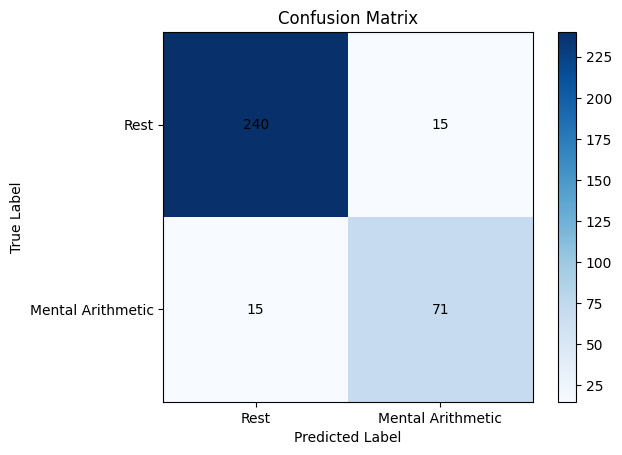

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure()
plt.imshow(cm, cmap="Blues") # Changed to "Blues" colormap
plt.title("Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

classes = ["Rest", "Mental Arithmetic"]
plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

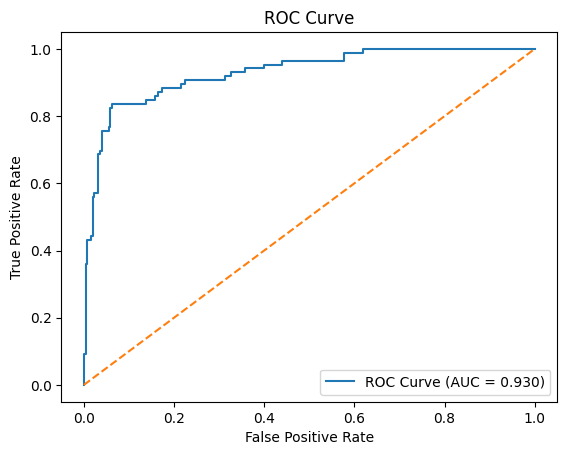

In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


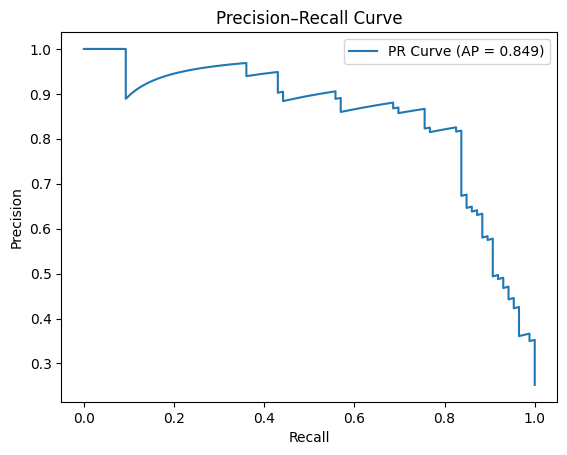

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(y_true, y_prob)
pr_auc = average_precision_score(y_true, y_prob)

plt.figure()
plt.plot(recall, precision, label=f"PR Curve (AP = {pr_auc:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend()
plt.show()


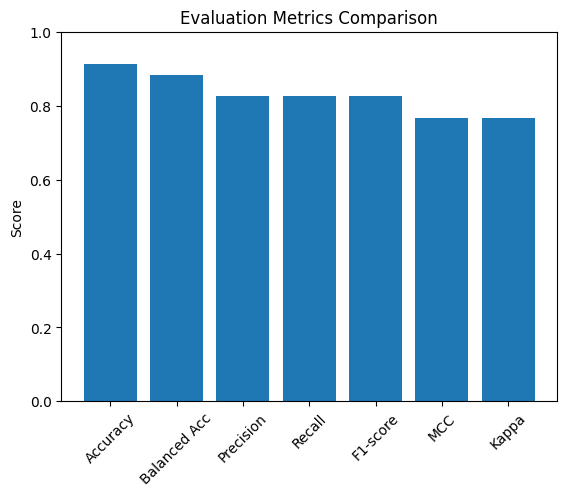

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score
)

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
    "Precision": precision_score(y_true, y_pred),
    "Recall": recall_score(y_true, y_pred),
    "F1-score": f1_score(y_true, y_pred),
    "MCC": matthews_corrcoef(y_true, y_pred),
    "Kappa": cohen_kappa_score(y_true, y_pred)
}

plt.figure()
plt.bar(metrics.keys(), metrics.values())
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.title("Evaluation Metrics Comparison")
plt.ylabel("Score")
plt.show()


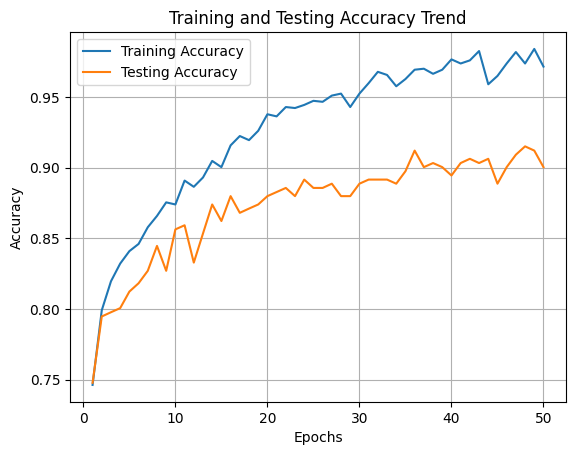

In [ ]:
import matplotlib.pyplot as plt

# Epochs
epochs = list(range(1, 51))

# Training accuracy (from your logs)
train_acc = [
    0.7463, 0.7991, 0.8196, 0.8321, 0.8409,
    0.8460, 0.8578, 0.8658, 0.8754, 0.8739,
    0.8908, 0.8864, 0.8930, 0.9047, 0.9003,
    0.9157, 0.9223, 0.9194, 0.9260, 0.9377,
    0.9362, 0.9428, 0.9421, 0.9443, 0.9472,
    0.9465, 0.9509, 0.9523, 0.9428, 0.9523,
    0.9597, 0.9677, 0.9655, 0.9575, 0.9626,
    0.9692, 0.9699, 0.9663, 0.9692, 0.9765,
    0.9736, 0.9758, 0.9824, 0.9589, 0.9648,
    0.9736, 0.9817, 0.9736, 0.9839, 0.9714
]

# Testing accuracy (from your logs)
test_acc = [
    0.7478, 0.7947, 0.7977, 0.8006, 0.8123,
    0.8182, 0.8270, 0.8446, 0.8270, 0.8563,
    0.8592, 0.8328, 0.8534, 0.8739, 0.8622,
    0.8798, 0.8680, 0.8710, 0.8739, 0.8798,
    0.8827, 0.8856, 0.8798, 0.8915, 0.8856,
    0.8856, 0.8886, 0.8798, 0.8798, 0.8886,
    0.8915, 0.8915, 0.8915, 0.8886, 0.8974,
    0.9120, 0.9003, 0.9032, 0.9003, 0.8944,
    0.9032, 0.9062, 0.9032, 0.9062, 0.8886,
    0.9003, 0.9091, 0.9150, 0.9120, 0.9003
]

# Plot
plt.figure()
plt.plot(epochs, train_acc, label="Training Accuracy")
plt.plot(epochs, test_acc, label="Testing Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Testing Accuracy Trend")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
!pip install shap


In [ ]:
import shap
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

shap.initjs()


In [ ]:
class WrappedModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        return self.softmax(self.model(x))


wrapped_model = WrappedModel(model_feat).to(device)
wrapped_model.eval()


WrappedModel(
  (model): FeatureMLP(
    (net): Sequential(
      (0): Linear(in_features=32, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=32, bias=True)
      (3): ReLU()
      (4): Linear(in_features=32, out_features=2, bias=True)
    )
  )
  (softmax): Softmax(dim=1)
)

In [ ]:
background = torch.tensor(
    Xf_train[:100],
    dtype=torch.float32
).to(device)


In [ ]:
explainer = shap.GradientExplainer(
    wrapped_model,
    background
)


In [ ]:
import torch.nn as nn

class WrappedModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        return self.softmax(self.model(x))


In [ ]:
bands = ["Theta", "Alpha", "Beta", "Energy"]

num_features = Xf_train.shape[1]
num_channels = num_features // 4

feature_names = []

for ch in range(num_channels):
    for band in bands:
        feature_names.append(f"Ch{ch}_{band}")

feature_names = feature_names[:num_features]

print("Total features:", len(feature_names))


Total features: 32


In [ ]:
sample_global = torch.tensor(
    Xf_test[:200],
    dtype=torch.float32
).to(device)

shap_values_global = explainer.shap_values(sample_global)


In [ ]:
idx = 10   # choose any window

sample_local = torch.tensor(
    Xf_test[idx:idx+1],
    dtype=torch.float32
).to(device)

shap_values_local = explainer.shap_values(sample_local)


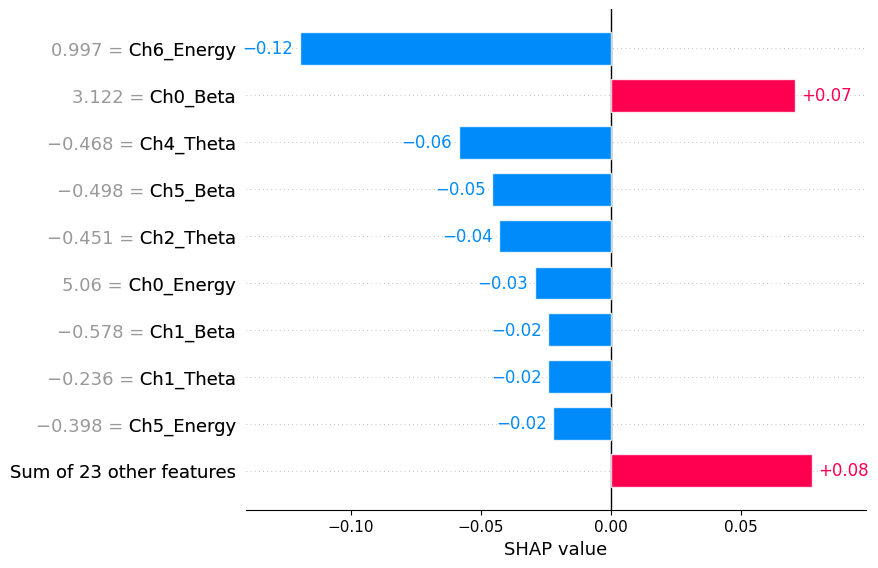

In [ ]:
shap.plots.bar(
    shap.Explanation(
        values=shap_values_local[0, :, 1],
        base_values=0,
        data=Xf_test[idx],
        feature_names=feature_names
    )
)


In [ ]:
subject_id = np.unique(subj_test)[0]

print("Explaining Subject:", subject_id)

mask = subj_test == subject_id
X_subject = Xf_test[mask]

print("Windows found:", X_subject.shape)


Explaining Subject: 0
Windows found: (9, 32)


In [ ]:
subject_tensor = torch.tensor(
    X_subject,
    dtype=torch.float32
).to(device)

shap_values_subject = explainer.shap_values(subject_tensor)


/tmp/ipython-input-3375972891.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


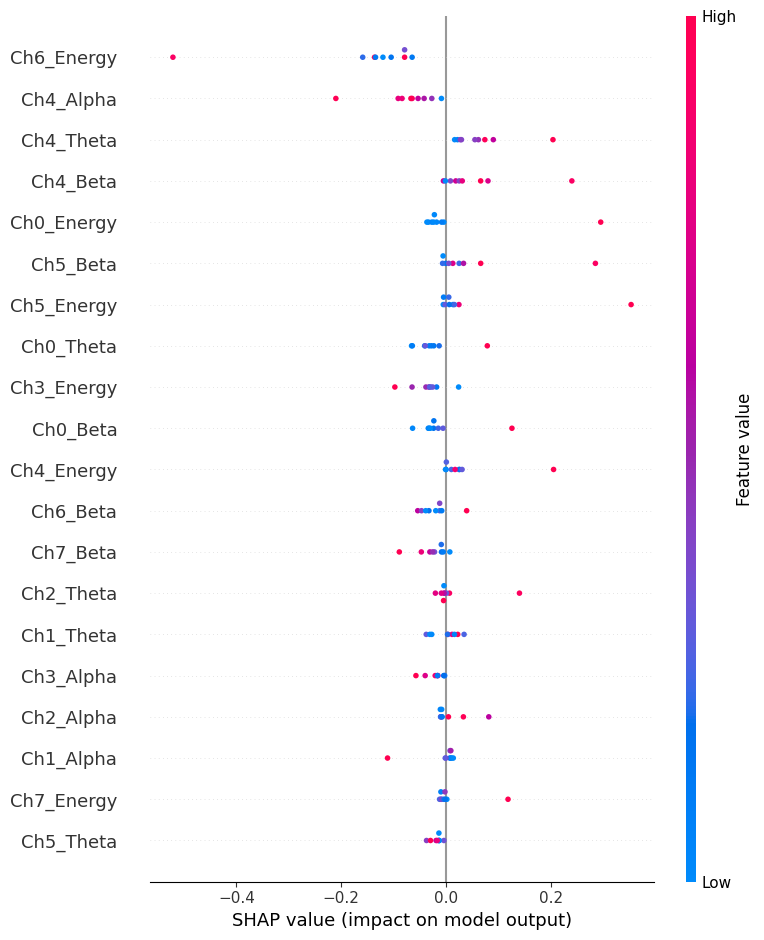

In [ ]:
shap.summary_plot(
    shap_values_subject[:, :, 1],
    X_subject,
    feature_names=feature_names
)


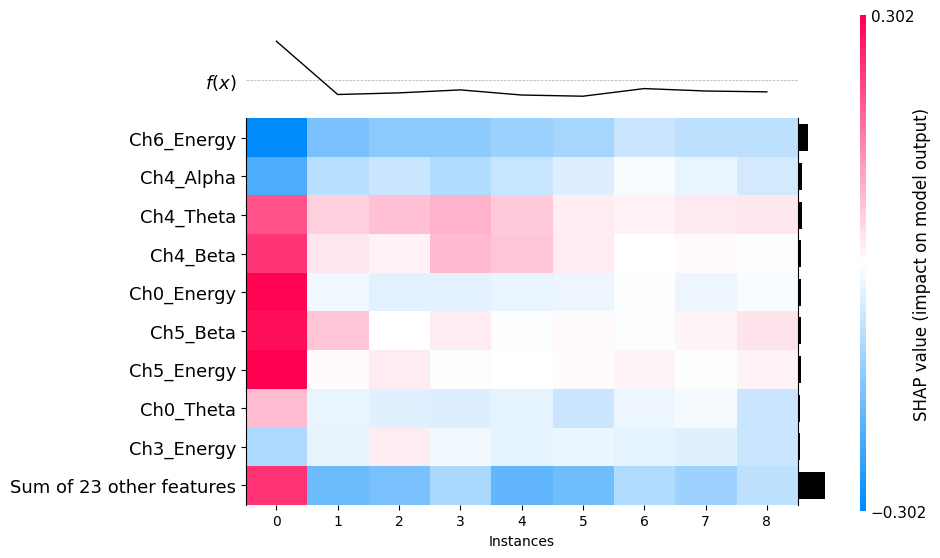

<Axes: xlabel='Instances'>

In [ ]:
shap.plots.heatmap(
    shap.Explanation(
        values=shap_values_subject[:, :, 1],
        data=X_subject,
        feature_names=feature_names
    )
)


In [ ]:
mean_importance = np.abs(
    shap_values_global[:, :, 1]
).mean(axis=0)

importance_order = np.argsort(mean_importance)[::-1]

for i in importance_order[:10]:
    print(feature_names[i], ":", mean_importance[i])


Ch4_Alpha : 0.09481301656269796
Ch6_Energy : 0.09370327145744099
Ch0_Theta : 0.09010495245197474
Ch4_Beta : 0.0774770410838423
Ch5_Beta : 0.07617499406629893
Ch4_Theta : 0.0715776686560972
Ch0_Energy : 0.058903187178315816
Ch0_Beta : 0.05765768676202598
Ch3_Energy : 0.05643935573106082
Ch1_Theta : 0.05496476526182891


In [ ]:
import torch
import torch.nn.functional as F

# Put model in evaluation mode
model_feat.eval()

THRESHOLD = 0.35  # calibrated threshold

# Show available samples
print(f"Total test samples available: {len(Xf_test)}")

# ---- USER INPUT ----
sample_idx = int(input("Enter sample index (0 to {}): ".format(len(Xf_test)-1)))

# Prepare selected sample
sample = torch.tensor(
    Xf_test[sample_idx:sample_idx+1],
    dtype=torch.float32
).to(device)

# Model prediction
with torch.no_grad():
    logits = model_feat(sample)
    probs = F.softmax(logits, dim=1)

prob_rest = probs[0, 0].item()
prob_task = probs[0, 1].item()

prediction = "Mental Arithmetic" if prob_task >= THRESHOLD else "Resting State"
true_label = "Mental Arithmetic" if yf_test[sample_idx] == 1 else "Resting State"

# ---- OUTPUT ----
print("\n----- PREDICTION RESULT -----")
print(f"Selected Sample Index : {sample_idx}")
print(f"True Label            : {true_label}")
print(f"P(Rest)               : {prob_rest:.3f}")
print(f"P(Mental Arithmetic)  : {prob_task:.3f}")
print(f"Final Prediction      : {prediction}")
print("-----------------------------")


Total test samples available: 341
Enter sample index (0 to 340): 7

----- PREDICTION RESULT -----
Selected Sample Index : 7
True Label            : Resting State
P(Rest)               : 1.000
P(Mental Arithmetic)  : 0.000
Final Prediction      : Resting State
-----------------------------
